# Оценка результатов A/B-теста геймификации на образовательной платформе

**Задача.** Продуктовая команда добавила в личный кабинет ученика геймификацию (систему достижений за регулярное решение задач) и запустила A/B-тест на 3 недели (04.05–24.05.2026). Группа A — старый интерфейс, группа B — интерфейс с геймификацией. Нужно решить, раскатывать функцию на всех, дорабатывать или отказаться.

**Данные.** `ab_test_users_groups.csv` — пользователь, группа, дата регистрации, класс. `ab_test_events.csv` — события: вход, начало и завершение домашнего задания, возвраты на 7-й и 14-й день.

**Метрики.** Completion Rate (доля завершивших не менее 4 ДЗ), Retention 7 и 14 дня, доля решённых ДЗ, время до первого ДЗ.

**План.** Очистка данных, проверка корректности теста, метрики по пользователям, воронка и распределения, выбор критериев, расчёт, мощность и MDE, сегменты по классам, вывод.

Пользователи рандомизировались по группам, поэтому анализирую на уровне пользователя: одна строка — один пользователь. Считать тест по событиям нельзя: события одного человека зависимы, и p-value получилось бы слишком оптимистичным.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests

plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
SEED = 42

## 1. Данные и первичный осмотр

In [2]:
groups = pd.read_csv('ab_test_users_groups.csv')
events = pd.read_csv('ab_test_events.csv')

print(groups.shape, events.shape)
display(groups.head())
display(events.head())

(6008, 4) (179330, 3)


,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11


,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started


In [3]:
print(groups.info())
print(groups.describe(include='all'))
print(groups.isna().sum())
print(groups.nunique())
print('--------------')
print(events.info())
print(events.describe(include='all'))
print(events.isna().sum())
print(events.nunique())
print('------')
print(events['event_type'].value_counts())
print('------')
events['timestamp'] = pd.to_datetime(events['timestamp'], errors='coerce')
print(events['timestamp'].min(), events['timestamp'].max())
print(events['timestamp'].isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      6008 non-null   object
 1   group        6008 non-null   object
 2   signup_date  6008 non-null   object
 3   grade        6008 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 187.9+ KB
None
        user_id group signup_date        grade
count      6008  6008        6008  6008.000000
unique     6000     2         370          NaN
top     U301554     A  2025-04-04          NaN
freq          2  3005          31          NaN
mean        NaN   NaN         NaN     7.962051
std         NaN   NaN         NaN     1.998141
min         NaN   NaN         NaN     5.000000
25%         NaN   NaN         NaN     6.000000
50%         NaN   NaN         NaN     8.000000
75%         NaN   NaN         NaN    10.000000
max         NaN   NaN         NaN    11.000000
user_id        0
group     

В `groups` 6008 строк, но уникальных `user_id` только 6000, значит, часть пользователей встречается дважды. В `events` есть полные дубли строк, а у отдельных пользователей до 842 событий при среднем около 30, что похоже на ботов. Названия групп и типов событий без опечаток, пропусков нет, период событий 04.05–24.05.2026 (21 день).

## 2. Очистка данных

**Дубли и пересечение групп.** Смотрю пользователей, которые числятся в двух группах, и полные дубли событий.

In [4]:
dups = groups[groups['user_id'].duplicated(keep=False)].sort_values('user_id')
print(dups)
print(events.duplicated().sum())

      user_id group signup_date  grade
357   U300357     A  2026-03-19      9
6000  U300357     B  2026-03-19      9
460   U300460     B  2025-08-12      6
6001  U300460     A  2025-08-12      6
920   U300920     B  2025-04-09     10
6002  U300920     A  2025-04-09     10
1014  U301014     A  2026-03-28     10
6003  U301014     B  2026-03-28     10
1087  U301087     B  2025-06-27     10
6004  U301087     A  2025-06-27     10
1367  U301367     B  2025-09-03      8
6005  U301367     A  2025-09-03      8
1554  U301554     A  2025-09-25      9
6006  U301554     B  2025-09-25      9
5216  U305216     B  2025-07-17      9
6007  U305216     A  2025-07-17      9
2


In [5]:
both = dups['user_id'].unique()
groups = groups[~groups['user_id'].isin(both)]
events = events[~events['user_id'].isin(both)]
events = events.drop_duplicates()
print(groups.shape, events.shape, groups['user_id'].is_unique)

(5992, 4) (179111, 3) True


In [6]:
print(groups['group'].value_counts())

group
A    2997
B    2995
Name: count, dtype: int64


In [7]:
events['timestamp'] = pd.to_datetime(events['timestamp'], errors='coerce')
print(events['timestamp'].isna().sum())
print(events['timestamp'].min(), events['timestamp'].max())

0
2026-05-04 00:06:44 2026-05-24 23:55:43


**Боты.** Считаю число событий на пользователя.

count    5992.000000
mean       29.891689
std        34.016822
min         6.000000
50%        28.000000
90%        37.000000
99%        45.090000
99.9%     770.009000
max       842.000000
dtype: float64
user_id
U303729    842
U304167    829
U305378    793
U302840    790
U304266    780
U300573    771
U300733    770
U302379    765
U300281    760
U300158    738
U304499    729
U303438    711
U300628     52
U301601     51
U303387     51
U300180     50
U300042     49
U305026     49
U300388     49
U302161     49
dtype: int64


<Axes: ylabel='Frequency'>

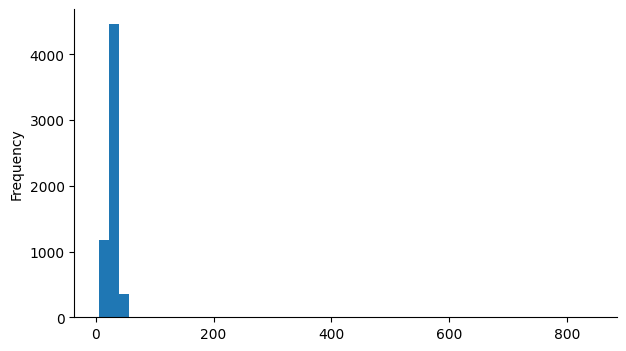

In [8]:
per_user = events.groupby('user_id').size()
print(per_user.describe(percentiles=[.5, .9, .99, .999]))
print(per_user.sort_values(ascending=False).head(20))
per_user.plot(kind='hist', bins=50)

In [9]:
bots = per_user[per_user > 100].index
print(len(bots))
print(groups[groups['user_id'].isin(bots)]['group'].value_counts())

12
group
B    7
A    5
Name: count, dtype: int64


In [10]:
groups = groups[~groups['user_id'].isin(bots)]
events = events[~events['user_id'].isin(bots)]
print(groups.shape, events.shape)

(5980, 4) (169833, 3)


In [11]:
print(events.groupby('user_id').size().describe())

count    5980.000000
mean       28.400167
std         6.766720
min         6.000000
25%        24.000000
50%        28.000000
75%        33.000000
max        52.000000
dtype: float64


**Итог очистки:**
- 8 пользователей числились в обеих группах, удалил их из обеих таблиц: неизвестно, какой интерфейс они видели.
- 2 полных дубля строк в `events` удалил.
- 12 ботов (711–842 события при норме до 52), 7 из них в B и 5 в A, удалил. Порог 100 событий выбран по разрыву в данных: у остальных пользователей максимум 52.
- После очистки: 5980 пользователей и 169 833 события.

## 3. Проверка корректности эксперимента

In [12]:
overlap = groups.groupby('user_id')['group'].nunique()
print((overlap > 1).sum())

0


In [13]:
counts = groups['group'].value_counts()
nA, nB = counts['A'], counts['B']
n = nA + nB
print(nA, nB)
print(stats.chisquare(f_obs=[nA, nB], f_exp=[n/2, n/2]))

2992 2988
Power_divergenceResult(statistic=np.float64(0.0026755852842809363), pvalue=np.float64(0.9587469721447145))


In [14]:
ct = pd.crosstab(groups['group'], groups['grade'])
print(ct)
chi2, p, dof, exp = stats.chi2_contingency(ct)
print(p)

grade   5    6    7    8    9    10   11
group                                   
A      446  446  402  454  430  409  405
B      416  462  435  431  379  438  427
0.23723332342252845


Пересечений между группами не осталось. SRM нет: в группах 2992 и 2988 пользователей, p = 0,96 (хи-квадрат согласия против деления 50/50). Распределение по классам в A и B не различается (p = 0,24), группы сопоставимы.

## 4. Метрики на уровне пользователя

In [15]:
first_ts = events.groupby('user_id')['timestamp'].min().rename('first_ts')
print(first_ts.head())

user_id
U300000   2026-05-04 19:36:00
U300001   2026-05-04 20:12:00
U300002   2026-05-06 18:47:00
U300003   2026-05-04 19:43:00
U300004   2026-05-04 19:09:00
Name: first_ts, dtype: datetime64[ns]


In [16]:
ue = pd.crosstab(events['user_id'], events['event_type'])
print(ue['homework_completed'].value_counts().sort_index())
print((ue['homework_completed'] >= 1).mean())

homework_completed
0      106
1      432
2      784
3     1062
4     1075
5      881
6      593
7      441
8      278
9      173
10      93
11      35
12      15
13      10
14       1
15       1
Name: count, dtype: int64
0.9822742474916388


98% пользователей завершили хотя бы одно ДЗ, поэтому такой критерий не различает группы. Для Completion Rate беру порог не менее 4 завершённых ДЗ: это около медианы по всем пользователям, порог выбран без разбивки по группам. Устойчивость проверю на порогах 3 и 5.

In [17]:
ret7  = (ue['return_visit_d7']  >= 1).astype(int)
ret14 = (ue['return_visit_d14'] >= 1).astype(int)

end = events['timestamp'].max()
users_tmp = first_ts.to_frame().join(ret14)
users_tmp['eligible14'] = users_tmp['first_ts'] + pd.Timedelta(days=14) <= end
print(users_tmp['eligible14'].mean())
print(users_tmp.groupby('eligible14')['return_visit_d14'].mean())

0.9968227424749164
eligible14
False    0.157895
True     0.325784
Name: return_visit_d14, dtype: float64


У 99,7% пользователей до конца теста было не менее 14 дней, поэтому из расчёта Retention 14 исключаю оставшихся (около 19 человек), у них не было времени вернуться. Так же поступаю с Retention 7 и окном в 7 дней.

In [18]:
started = ue['homework_started']
completed = ue['homework_completed']
solve_rate = completed / started.replace(0, np.nan)
print(solve_rate.describe())
print((solve_rate > 1).sum())

first_login = events[events['event_type'] == 'login'].groupby('user_id')['timestamp'].min()
first_hw = events[events['event_type'] == 'homework_started'].groupby('user_id')['timestamp'].min()
ttv_hours = (first_hw - first_login).dt.total_seconds() / 3600
print(ttv_hours.describe())
print((ttv_hours < 0).sum())

count    5980.000000
mean        0.391986
std         0.175064
min         0.000000
25%         0.272727
50%         0.384615
75%         0.500000
max         1.000000
dtype: float64
0
count    5980.000000
mean        4.581739
std        17.037440
min         0.016667
25%         0.050000
50%         0.100000
75%         0.133333
max       217.966667
Name: timestamp, dtype: float64
0


`solve_rate` — доля завершённых ДЗ от начатых, значений больше 1 нет. `ttv_hours` — часы от первого входа до первого начатого ДЗ: медиана около 6 минут, среднее 4,6 часа из-за длинного хвоста (до 218 часов), отрицательных значений нет.

In [19]:
users = ue.reset_index().merge(groups[['user_id', 'group', 'grade']], on='user_id')
users = users.merge(first_ts.reset_index(), on='user_id')
end = events['timestamp'].max()

users['completed'] = (users['homework_completed'] >= 4).astype(int)   # порог 4: около медианы числа ДЗ, обоснование ниже
users['ret7']  = (users['return_visit_d7']  >= 1).astype(int)
users['ret14'] = (users['return_visit_d14'] >= 1).astype(int)
users['solve_rate'] = users['homework_completed'] / users['homework_started']
users['ttv_hours'] = users['user_id'].map(ttv_hours)

users['elig7']  = users['first_ts'] + pd.Timedelta(days=7)  <= end
users['elig14'] = users['first_ts'] + pd.Timedelta(days=14) <= end

print(users.shape, users['user_id'].is_unique)
print(users.groupby('group')[['completed', 'ret7', 'ret14', 'solve_rate']].mean())
print(users.groupby('group')['ttv_hours'].median())

(5980, 16) True
       completed      ret7     ret14  solve_rate
group                                           
A       0.491310  0.726939  0.288102    0.346066
B       0.711513  0.779786  0.362450    0.437967
group
A    0.083333
B    0.100000
Name: ttv_hours, dtype: float64


In [20]:
users['fast_start'] = (users['ttv_hours'] <= 1).astype(int)
print(users.groupby('group')['fast_start'].mean())

group
A    0.904078
B    0.899598
Name: fast_start, dtype: float64


**Определения метрик**
- `completed` — завершил не менее 4 ДЗ.
- `ret7`, `ret14` — у пользователя есть событие `return_visit_d7` или `return_visit_d14`.
- `solve_rate` — завершённые ДЗ / начатые.
- `fast_start` — первое ДЗ начато в течение часа после первого входа. `ttv_hours` сильно скошена, поэтому вместо среднего использую долю.

## 5. Воронка и распределения

In [21]:
funnel = pd.DataFrame({
    'login': users['login'] >= 1,
    'hw_started': users['homework_started'] >= 1,
    'hw_done_1': users['homework_completed'] >= 1,
    'completed': users['completed'] == 1,
})
funnel['group'] = users['group']

counts = funnel.groupby('group').sum()
print(counts)

share = funnel.groupby('group').mean()
print(share.round(3))

step = counts.T
step_conv = step / step.shift(1)
print(step_conv.round(3))

       login  hw_started  hw_done_1  completed
group                                         
A       2992        2992       2921       1470
B       2988        2988       2953       2126
       login  hw_started  hw_done_1  completed
group                                         
A        1.0         1.0      0.976      0.491
B        1.0         1.0      0.988      0.712
group           A      B
login         NaN    NaN
hw_started  1.000  1.000
hw_done_1   0.976  0.988
completed   0.503  0.720


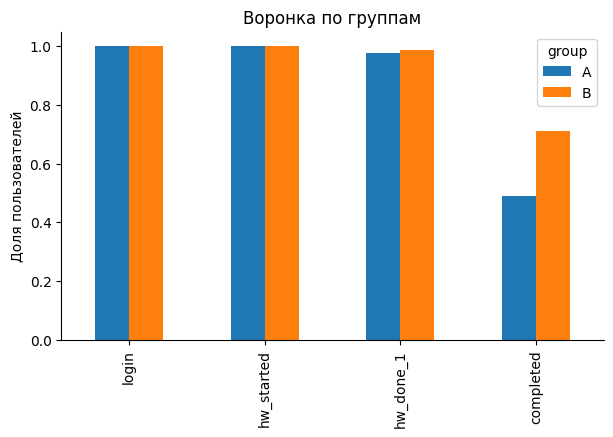

In [22]:
share.T.plot(kind='bar')
plt.ylabel('Доля пользователей')
plt.title('Воронка по группам')
plt.show()

На шагах «вход» и «начал ДЗ» группы не отличаются (100%). Различие появляется на завершении курса: из тех, кто сделал хотя бы одно ДЗ, до `completed` дошли 50,3% в A и 72,0% в B.

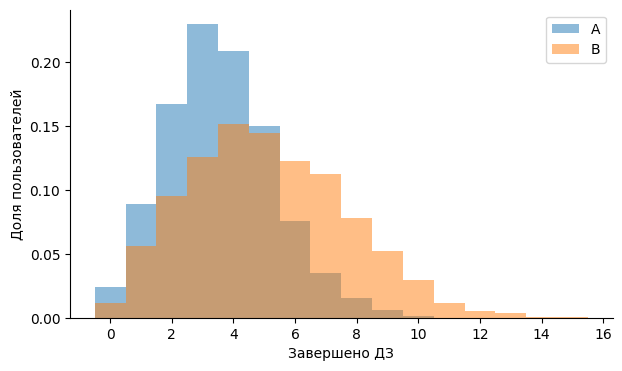

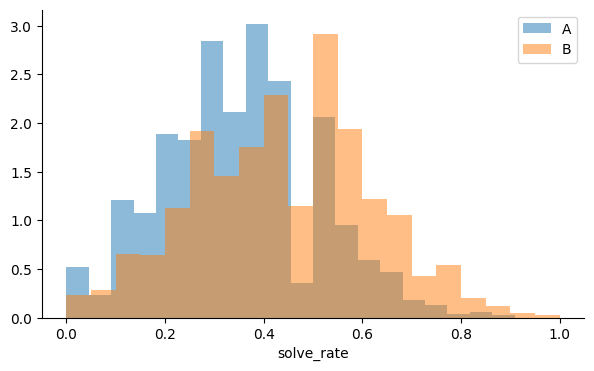

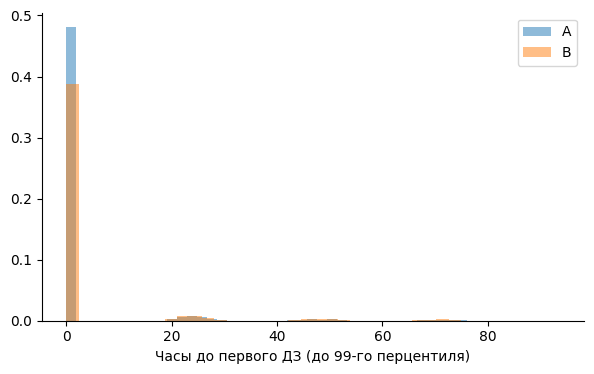

In [23]:
bins = np.arange(0, users['homework_completed'].max() + 2) - 0.5
for g, color in [('A', 'tab:blue'), ('B', 'tab:orange')]:
    plt.hist(users.loc[users['group'] == g, 'homework_completed'],
             bins=bins, alpha=0.5, density=True, label=g, color=color)
plt.xlabel('Завершено ДЗ')
plt.ylabel('Доля пользователей')
plt.legend()
plt.show()

for g in ['A', 'B']:
    plt.hist(users.loc[users['group'] == g, 'solve_rate'],
             bins=20, alpha=0.5, density=True, label=g)
plt.legend(); plt.xlabel('solve_rate'); plt.show()

# обрезать хвост по 99-му перцентилю
cut = users['ttv_hours'].quantile(0.99)
for g in ['A', 'B']:
    plt.hist(users.loc[(users['group'] == g) & (users['ttv_hours'] <= cut), 'ttv_hours'],
             bins=40, alpha=0.5, density=True, label=g)
plt.legend(); plt.xlabel('Часы до первого ДЗ (до 99-го перцентиля)'); plt.show()

**Выводы по графикам**
1. `homework_completed`: распределение B сдвинуто вправо. У A пик на 3 ДЗ, у B на 4–5, и у B заметно толще хвост на 6–10 ДЗ.
2. `solve_rate`: у B тоже сдвиг вправо. Зубцы на графике возникают из-за отношений небольших целых чисел (1/2, 1/3 и т. д.), настоящей двугорбости нет.
3. `ttv_hours`: почти все начинают первое ДЗ сразу, небольшие всплески на 24, 48 и 72 часах. Доли быстрых стартов в группах почти одинаковы (90,4% и 90,0%).

## 6. Выбор критерия

In [24]:
print(users.groupby('group')[['homework_completed', 'solve_rate', 'ttv_hours']].skew())

       homework_completed  solve_rate  ttv_hours
group                                           
A                0.400898    0.201842   5.489561
B                0.357023    0.000694   5.333673


- **completed, ret7, ret14, fast_start** — бинарные метрики. Сравниваю доли в двух независимых группах z-тестом для двух долей (около 3000 пользователей в группе, условия применимости выполнены).
- **homework_completed, solve_rate** — скошены вправо (гистограммы, коэффициент асимметрии), поэтому использую критерий Манна — Уитни. Для среднего числа ДЗ строю bootstrap-интервал.
- **ttv_hours** — бимодальна с очень длинным хвостом (сразу или на следующие сутки), поэтому вместо среднего сравниваю долю быстрых стартов.
- **Гипотезы:** H0 — метрика в A и B не отличается, H1 — отличается. Проверка двусторонняя, уровень значимости 0,05. Так как метрик несколько, применяю поправку Холма.

## 7. Статистический расчёт

**Completion Rate** (основная метрика)

In [25]:
a = users[users['group'] == 'A']['completed']
b = users[users['group'] == 'B']['completed']
cA, nA = a.sum(), len(a)
cB, nB = b.sum(), len(b)

stat, p = proportions_ztest(count=[cB, cA], nobs=[nB, nA])
low, high = confint_proportions_2indep(cB, nB, cA, nA, compare='diff')
print(cB/nB, cA/nA, cB/nB - cA/nA)
print(p, (low, high))

0.7115127175368139 0.4913101604278075 0.22020255710900638
9.951260660684869e-68 (np.float64(0.19584301759476044), np.float64(0.24418069962016084))


Completion в B 71,2% против 49,1% в A, разница +22,0 п.п. (95% ДИ [19,6; 24,4], p < 0,001), относительный прирост около 45%.

**Retention, скорость старта и устойчивость к порогу Completion**

In [26]:
def ab_prop(df, col):
    a = df[df['group'] == 'A'][col]
    b = df[df['group'] == 'B'][col]
    cA, nA = a.sum(), len(a)
    cB, nB = b.sum(), len(b)
    stat, p = proportions_ztest([cB, cA], [nB, nA])
    low, high = confint_proportions_2indep(cB, nB, cA, nA, compare='diff')
    print(f"{col}: A={cA/nA:.3f} (n={nA}), B={cB/nB:.3f} (n={nB}), "
          f"diff={cB/nB - cA/nA:+.3f}, CI=[{low:.3f}; {high:.3f}], p={p:.2g}")
    return p

p_ret7  = ab_prop(users[users['elig7']],  'ret7')
p_ret14 = ab_prop(users[users['elig14']], 'ret14')
p_fast  = ab_prop(users, 'fast_start')

for k in [3, 4, 5]:
    users['c_tmp'] = (users['homework_completed'] >= k).astype(int)
    print('порог', k, end=': ')
    ab_prop(users, 'c_tmp')

ret7: A=0.727 (n=2991), B=0.780 (n=2988), diff=+0.053, CI=[0.031; 0.074], p=2.4e-06
ret14: A=0.289 (n=2980), B=0.363 (n=2981), diff=+0.074, CI=[0.051; 0.098], p=9e-10
fast_start: A=0.904 (n=2992), B=0.900 (n=2988), diff=-0.004, CI=[-0.020; 0.011], p=0.56
порог 3: c_tmp: A=0.721 (n=2992), B=0.837 (n=2988), diff=+0.117, CI=[0.096; 0.138], p=1.4e-27
порог 4: c_tmp: A=0.491 (n=2992), B=0.712 (n=2988), diff=+0.220, CI=[0.196; 0.244], p=1e-67
порог 5: c_tmp: A=0.283 (n=2992), B=0.560 (n=2988), diff=+0.277, CI=[0.253; 0.301], p=2e-104


Retention 7: +5,3 п.п. (ДИ [3,1; 7,4]), Retention 14: +7,4 п.п. (ДИ [5,1; 9,8]), оба различия значимы. Доля быстрых стартов не изменилась (p = 0,56). Эффект по Completion положителен при любом пороге: +11,7 п.п. (порог 3), +22,0 (порог 4), +27,7 (порог 5), вывод не зависит от выбранного порога.

**Число ДЗ и доля решённых**

In [27]:
for col in ['homework_completed', 'solve_rate']:
    a = users.loc[users['group'] == 'A', col]
    b = users.loc[users['group'] == 'B', col]
    u, p = stats.mannwhitneyu(b, a, alternative='two-sided')
    print(f"{col}: медиана A={a.median():.2f}, B={b.median():.2f}, p={p:.2g}")

rng = np.random.default_rng(SEED)
a = users.loc[users['group'] == 'A', 'homework_completed'].values
b = users.loc[users['group'] == 'B', 'homework_completed'].values
diffs = [rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(5000)]
print(np.percentile(diffs, [2.5, 97.5]))

homework_completed: медиана A=3.00, B=5.00, p=3.6e-127


solve_rate: медиана A=0.33, B=0.44, p=8.6e-90


[1.41385137 1.63734686]


Медиана завершённых ДЗ в A равна 3, в B равна 5. Доверительный интервал для разницы средних [1,41; 1,64] ДЗ не включает ноль. Медиана `solve_rate` 0,33 против 0,44. Оба различия по Манну — Уитни значимы.

**Поправка на множественные сравнения (Холм)**

In [28]:
a = users[users['group'] == 'A']['completed']; b = users[users['group'] == 'B']['completed']
p_comp = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])[1]

pvals = [p_comp, p_ret7, p_ret14, p_fast]
reject, p_adj, _, _ = multipletests(pvals, method='holm')
print(pd.DataFrame({'metric': ['completed', 'ret7', 'ret14', 'fast_start'],
                    'p': pvals, 'p_adj': p_adj, 'значимо': reject}))

       metric             p         p_adj  значимо
0   completed  9.951261e-68  3.980504e-67     True
1        ret7  2.371635e-06  4.743271e-06     True
2       ret14  9.000297e-10  2.700089e-09     True
3  fast_start  5.605128e-01  5.605128e-01    False


После поправки значимыми остаются Completion, Retention 7 и Retention 14. `fast_start` значимо не различается.

## 8. Мощность и MDE

In [29]:
nA, nB = 2992, 2988
pA = users[users['group'] == 'A']['completed'].mean()

h = NormalIndPower().solve_power(effect_size=None, nobs1=nA, alpha=0.05,
                                 power=0.8, ratio=nB / nA)
# перевод Cohen's h обратно в долю
pB_min = np.sin(np.arcsin(np.sqrt(pA)) + h / 2) ** 2
print(h, pB_min - pA)

0.07245732571545306 0.036214304721211676


In [30]:
h2 = proportion_effectsize(pA + 0.02, pA)
n_need = NormalIndPower().solve_power(effect_size=h2, nobs1=None, alpha=0.05, power=0.8, ratio=1)
print(n_need)

9809.699997966552


При группах около 2990 пользователей минимальный эффект, который тест обнаруживает с мощностью 80% (alpha = 0,05), составляет около 3,6 п.п. по Completion. Наблюдаемый эффект (22 п.п.) намного больше, поэтому вывод надёжен. Чтобы поймать эффект в 2 п.п., потребовалось бы около 9800 пользователей на группу.

## 9. Сегменты по классам

Бриф указывает, что эффект может отличаться по классам, поэтому считаю Completion отдельно для каждого класса и применяю поправку Холма.

In [31]:
rows = []
for g, d in users.groupby('grade'):
    a = d[d['group'] == 'A']['completed']
    b = d[d['group'] == 'B']['completed']
    stat, p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
    low, high = confint_proportions_2indep(b.sum(), len(b), a.sum(), len(a), compare='diff')
    rows.append({'grade': g, 'nA': len(a), 'nB': len(b),
                 'A': a.mean(), 'B': b.mean(), 'diff': b.mean() - a.mean(),
                 'low': low, 'high': high, 'p': p})
seg = pd.DataFrame(rows)

reject, p_adj, _, _ = multipletests(seg['p'], method='holm')
seg['p_adj'] = p_adj
seg['значимо'] = reject

out = seg.drop(columns='p').round(3)
out['p_adj'] = seg['p_adj'].map('{:.1e}'.format)
print(out.to_string(index=False))

 grade  nA  nB     A     B   diff    low   high   p_adj  значимо
     5 446 416 0.500 0.952  0.452  0.399  0.501 2.3e-48     True
     6 446 462 0.448 0.937  0.489  0.436  0.538 6.0e-57     True
     7 402 435 0.545 0.917  0.372  0.316  0.426 8.5e-34     True
     8 454 431 0.476 0.738  0.262  0.199  0.322 6.6e-15     True
     9 430 379 0.472 0.744  0.272  0.206  0.334 1.0e-14     True
    10 409 438 0.504 0.345 -0.159 -0.224 -0.092 5.7e-06     True
    11 405 427 0.501 0.344 -0.157 -0.222 -0.090 5.7e-06     True


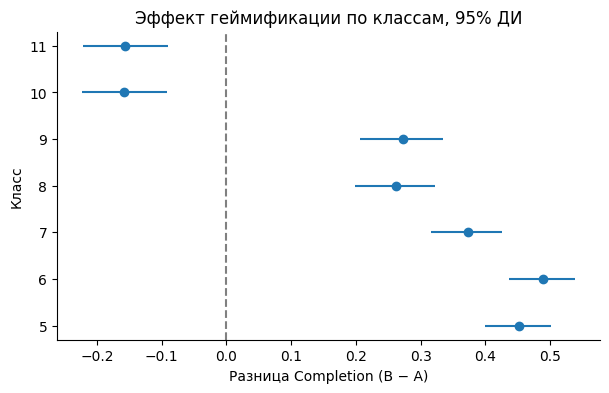

In [32]:
plt.errorbar(seg['diff'], seg['grade'],
             xerr=[seg['diff'] - seg['low'], seg['high'] - seg['diff']], fmt='o')
plt.axvline(0, color='gray', linestyle='--')
plt.yticks(seg['grade'])
plt.xlabel('Разница Completion (B − A)')
plt.ylabel('Класс')
plt.title('Эффект геймификации по классам, 95% ДИ')
plt.show()

Эффект на Completion сильно различается по классам. В 5–9 классах B лучше A на 26–49 п.п. (в классах 5–7 доля завершивших доходит до 92–95%). В 10 и 11 классах эффект отрицательный: разница около −16 п.п. (ДИ примерно [−22; −9]), в B курс завершают 34% против 50% в A. Все семь различий значимы после поправки Холма.

Общий плюс в 22 п.п. получается как среднее между положительными эффектами в младших классах и отрицательным в старших.

In [33]:
users['grade_group'] = np.where(users['grade'] <= 9, '5-9', '10-11')

for gg, d in users.groupby('grade_group'):
    print('классы', gg)
    ab_prop(d, 'completed')
    ab_prop(d[d['elig7']], 'ret7')
    ab_prop(d[d['elig14']], 'ret14')
    print()

классы 10-11
completed: A=0.502 (n=814), B=0.345 (n=865), diff=-0.158, CI=[-0.204; -0.111], p=5.7e-11
ret7: A=0.721 (n=814), B=0.680 (n=865), diff=-0.041, CI=[-0.085; 0.003], p=0.065
ret14: A=0.293 (n=813), B=0.253 (n=860), diff=-0.039, CI=[-0.082; 0.003], p=0.072

классы 5-9
completed: A=0.487 (n=2178), B=0.861 (n=2123), diff=+0.374, CI=[0.348; 0.399], p=3e-150
ret7: A=0.729 (n=2177), B=0.821 (n=2123), diff=+0.091, CI=[0.066; 0.116], p=9e-13
ret14: A=0.287 (n=2167), B=0.407 (n=2121), diff=+0.120, CI=[0.092; 0.148], p=1.3e-16



В классах 5–9 выигрывают все метрики: Completion +37,4 п.п. (49% → 86%), Retention 7 +9,1 п.п., Retention 14 +12,0 п.п., все различия значимы.

В классах 10–11 Completion падает на 15,8 п.п. (50% → 34%, p < 0,001). Retention 7 и 14 в B тоже ниже на 4 п.п., но эти различия на границе значимости (p = 0,065 и 0,072, ДИ включают ноль): снижение возвратов не подтверждено, но и исключить его нельзя.

## 10. Вывод и рекомендация

**Корректность эксперимента.** Из данных удалены 8 пользователей из обеих групп, 2 дубля событий и 12 ботов. После очистки SRM нет (2992 и 2988 пользователей, p = 0,96), группы сопоставимы по классам.

**Результат в целом.** Геймификация значимо повышает Completion Rate: 71,2% против 49,1% (+22,0 п.п., 95% ДИ [19,6; 24,4]), это около +45% относительно контроля. Вывод устойчив к выбору порога завершения (3, 4 и 5 ДЗ). Retention 7 вырос на 5,3 п.п., Retention 14 на 7,4 п.п. Все три различия остаются значимыми после поправки на множественные сравнения. Скорость старта первого ДЗ не изменилась.

**Эффект по классам.** В 5–9 классах геймификация работает: Completion +37,4 п.п. (49% → 86%), Retention 7 +9,1 п.п., Retention 14 +12,0 п.п. В 10–11 классах Completion падает на 15,8 п.п. (50% → 34%), а возвраты на 7-й и 14-й день в B ниже примерно на 4 п.п. (статистически не подтверждено, p = 0,065 и 0,072). Если раскатить функцию на всех, в целом метрика вырастет (около +2200 завершивших на 10 000 учеников), но старшеклассники будут получать результат хуже, чем сейчас.

**Рекомендация: не раскатывать на всех.** Включить геймификацию для 5–9 классов. Для 10–11 классов оставить прежний интерфейс и отправить механику на доработку.

**Ограничения.**
- В данных нет события «завершение модуля», поэтому Completion определён порогом в 4 завершённых ДЗ.
- Причины различий между классами по данным не видны. Возможное объяснение: механика достижений менее привлекательна старшеклассникам, но это гипотеза.
- Тест шёл 3 недели, долгосрочный эффект неизвестен.
- Внутри класса около 400–460 пользователей в группе, поэтому небольшие эффекты по отдельным классам тест бы не заметил.

**Следующий шаг.** Отдельный тест для 10–11 классов с доработанной механикой и расчётом размера выборки заранее; для 5–9 классов — наблюдение за Retention после запуска.